In [6]:
# 计算 GT_DIR 与 PRED_DIR 的 PSNR（每张 2x2 拼接图切成 4 张子图后统计）
import os
import glob
from pathlib import Path

import cv2
import numpy as np

# ===== 路径 =====
GT_DIR = "/home/viplab/liukejia/project/result/render_3d_stitched"
PRED_DIR = "/home/viplab/liukejia/project/result/inference_images"


def psnr(img1, img2, data_range=255.0):
    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10((data_range ** 2) / mse)


def list_images(folder):
    exts = ("*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG", "*.JPEG")
    files = []
    for ext in exts:
        files.extend(glob.glob(os.path.join(folder, ext)))
    return sorted(files)


def split_2x2(img):
    """把一张 2x2 拼接图切成 [tl, tr, bl, br] 4 张子图。"""
    h, w = img.shape[:2]
    h2, w2 = h // 2, w // 2
    return [
        img[0:h2, 0:w2],
        img[0:h2, w2:w],
        img[h2:h, 0:w2],
        img[h2:h, w2:w],
    ]


if not os.path.isdir(GT_DIR):
    print(f"未找到 GT_DIR: {GT_DIR}")
elif not os.path.isdir(PRED_DIR):
    print(f"未找到 PRED_DIR: {PRED_DIR}")
else:
    gt_files = list_images(GT_DIR)
    pred_files = list_images(PRED_DIR)

    print(f"GT 图片数: {len(gt_files)}")
    print(f"PRED 图片数: {len(pred_files)}")

    # 先尝试按文件名 stem 精确配对；失败则按排序一一配对
    pred_by_stem = {Path(p).stem: p for p in pred_files}
    pairs = []
    unmatched_gt = []

    for g in gt_files:
        stem = Path(g).stem
        if stem in pred_by_stem:
            pairs.append((g, pred_by_stem[stem]))
        else:
            unmatched_gt.append(g)

    if len(pairs) == 0:
        n = min(len(gt_files), len(pred_files))
        pairs = list(zip(gt_files[:n], pred_files[:n]))
        print("未找到同名文件，改为按排序顺序配对。")
    elif len(unmatched_gt) > 0:
        print(f"有 {len(unmatched_gt)} 张 GT 未匹配到同名 PRED，将忽略这些样本。")

    patch_psnr_values = []
    image_avg_records = []
    skipped_images = 0

    for gt_path, pred_path in pairs:
        gt_bgr = cv2.imread(gt_path, cv2.IMREAD_COLOR)
        pred_bgr = cv2.imread(pred_path, cv2.IMREAD_COLOR)
        if gt_bgr is None or pred_bgr is None:
            skipped_images += 1
            continue

        gt_rgb = cv2.cvtColor(gt_bgr, cv2.COLOR_BGR2RGB)
        pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)

        gt_patches = split_2x2(gt_rgb)
        pred_patches = split_2x2(pred_rgb)

        cur_vals = []
        for gt_patch, pred_patch in zip(gt_patches, pred_patches):
            if pred_patch.shape[:2] != gt_patch.shape[:2]:
                pred_patch = cv2.resize(
                    pred_patch,
                    (gt_patch.shape[1], gt_patch.shape[0]),
                    interpolation=cv2.INTER_AREA,
                )
            v = psnr(gt_patch, pred_patch, data_range=255.0)
            patch_psnr_values.append(v)
            cur_vals.append(v)

        image_avg_records.append((Path(gt_path).name, float(np.mean(cur_vals))))

    if len(patch_psnr_values) == 0:
        print("没有可计算的样本，请检查图片是否可读与配对规则。")
    else:
        vals = np.array(patch_psnr_values, dtype=np.float64)
        expected = 9 * 4
        print(f"已配对整图数: {len(image_avg_records)}，跳过整图数: {skipped_images}")
        print(f"子图 PSNR 样本数: {len(vals)}（若 9 张都有效应为 {expected}）")
        print(f"平均 PSNR: {vals.mean():.4f} dB")
        print(f"中位数 PSNR: {np.median(vals):.4f} dB")
        print(f"最小 PSNR: {vals.min():.4f} dB")
        print(f"最大 PSNR: {vals.max():.4f} dB")
        print(f"标准差: {vals.std():.4f} dB")

        print("\n前 5 张整图（4 子图均值）:")
        for name, v in image_avg_records[:5]:
            print(f"  {name}: {v:.4f} dB")

GT 图片数: 9
PRED 图片数: 9
已配对整图数: 9，跳过整图数: 0
子图 PSNR 样本数: 36（若 9 张都有效应为 36）
平均 PSNR: 14.6848 dB
中位数 PSNR: 14.6191 dB
最小 PSNR: 13.8809 dB
最大 PSNR: 15.3628 dB
标准差: 0.3596 dB

前 5 张整图（4 子图均值）:
  num123_-800_100_0_0007.png: 14.5865 dB
  num123_-800_150_0_0008.png: 14.3167 dB
  num123_-800_200_0_0009.png: 14.8078 dB
  num123_-850_100_0_0004.png: 14.4912 dB
  num123_-850_150_0_0005.png: 14.6714 dB


In [7]:
# 计算 SSIM / FID / KID（基于 2x2 切分后的子图分布）
import os
import glob
from pathlib import Path

import cv2
import numpy as np

# 可选依赖：若未安装会给出提示
try:
    import torch
    from torchmetrics.image.fid import FrechetInceptionDistance
    from torchmetrics.image.kid import KernelInceptionDistance
    HAS_TORCHMETRICS = True
except Exception as e:
    HAS_TORCHMETRICS = False
    _tm_import_err = e

try:
    from skimage.metrics import structural_similarity as ssim_fn
    HAS_SKIMAGE = True
except Exception as e:
    HAS_SKIMAGE = False
    _sk_import_err = e


def list_images(folder):
    exts = ("*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG", "*.JPEG")
    files = []
    for ext in exts:
        files.extend(glob.glob(os.path.join(folder, ext)))
    return sorted(files)


def split_2x2(img):
    h, w = img.shape[:2]
    h2, w2 = h // 2, w // 2
    return [
        img[0:h2, 0:w2],
        img[0:h2, w2:w],
        img[h2:h, 0:w2],
        img[h2:h, w2:w],
    ]


def build_pairs(gt_files, pred_files):
    pred_by_stem = {Path(p).stem: p for p in pred_files}
    pairs = []
    unmatched_gt = []
    for g in gt_files:
        stem = Path(g).stem
        if stem in pred_by_stem:
            pairs.append((g, pred_by_stem[stem]))
        else:
            unmatched_gt.append(g)

    if len(pairs) == 0:
        n = min(len(gt_files), len(pred_files))
        pairs = list(zip(gt_files[:n], pred_files[:n]))
        print("未找到同名文件，改为按排序顺序配对。")
    elif len(unmatched_gt) > 0:
        print(f"有 {len(unmatched_gt)} 张 GT 未匹配到同名 PRED，将忽略这些样本。")
    return pairs


if not os.path.isdir(GT_DIR):
    print(f"未找到 GT_DIR: {GT_DIR}")
elif not os.path.isdir(PRED_DIR):
    print(f"未找到 PRED_DIR: {PRED_DIR}")
else:
    gt_files = list_images(GT_DIR)
    pred_files = list_images(PRED_DIR)
    pairs = build_pairs(gt_files, pred_files)

    gt_patches_all = []
    pred_patches_all = []
    skipped_images = 0

    for gt_path, pred_path in pairs:
        gt_bgr = cv2.imread(gt_path, cv2.IMREAD_COLOR)
        pred_bgr = cv2.imread(pred_path, cv2.IMREAD_COLOR)
        if gt_bgr is None or pred_bgr is None:
            skipped_images += 1
            continue

        gt_rgb = cv2.cvtColor(gt_bgr, cv2.COLOR_BGR2RGB)
        pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)

        gt_patches = split_2x2(gt_rgb)
        pred_patches = split_2x2(pred_rgb)

        for gt_patch, pred_patch in zip(gt_patches, pred_patches):
            if pred_patch.shape[:2] != gt_patch.shape[:2]:
                pred_patch = cv2.resize(
                    pred_patch,
                    (gt_patch.shape[1], gt_patch.shape[0]),
                    interpolation=cv2.INTER_AREA,
                )
            gt_patches_all.append(gt_patch)
            pred_patches_all.append(pred_patch)

    n = len(gt_patches_all)
    print(f"已配对子图数: {n}（理论上 9 张整图时为 36）")
    print(f"跳过整图数: {skipped_images}")

    # ===== SSIM =====
    if not HAS_SKIMAGE:
        print("\n[SSIM] 缺少依赖 skimage，无法计算。")
        print(f"导入错误: {_sk_import_err}")
        print("可安装: pip install scikit-image")
    elif n == 0:
        print("\n[SSIM] 没有可计算样本。")
    else:
        ssim_vals = []
        for g, p in zip(gt_patches_all, pred_patches_all):
            v = ssim_fn(g, p, channel_axis=2, data_range=255)
            ssim_vals.append(float(v))
        ssim_vals = np.array(ssim_vals, dtype=np.float64)
        print("\n[SSIM]")
        print(f"平均 SSIM: {ssim_vals.mean():.6f}")
        print(f"中位数 SSIM: {np.median(ssim_vals):.6f}")
        print(f"最小 SSIM: {ssim_vals.min():.6f}")
        print(f"最大 SSIM: {ssim_vals.max():.6f}")
        print(f"标准差 SSIM: {ssim_vals.std():.6f}")

    # ===== LPIPS =====
    try:
        import lpips
        HAS_LPIPS = True
    except Exception as e:
        HAS_LPIPS = False
        _lpips_err = e

    if not HAS_LPIPS:
        print("\n[LPIPS] 缺少依赖 lpips，无法计算。")
        print(f"导入错误: {_lpips_err}")
        print("可安装: pip install lpips")
    elif n == 0:
        print("\n[LPIPS] 没有可计算样本。")
    else:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        lpips_model = lpips.LPIPS(net='alex').to(device)
        lpips_vals = []
        # 逐对计算 LPIPS（每个输入为 0-255 的 uint8 RGB）
        for g, p in zip(gt_patches_all, pred_patches_all):
            # 转为 float32 并归一化到 [-1,1]
            g_t = torch.from_numpy(((g.astype(np.float32)/255.0)*2.0 - 1.0).transpose(2,0,1)).unsqueeze(0).to(device)
            p_t = torch.from_numpy(((p.astype(np.float32)/255.0)*2.0 - 1.0).transpose(2,0,1)).unsqueeze(0).to(device)
            with torch.no_grad():
                v = lpips_model(g_t, p_t)
            lpips_vals.append(float(v.cpu().item()))
        lpips_vals = np.array(lpips_vals, dtype=np.float64)
        # per-image average（每4个子图一组）
        lpips_image_mean = []
        for i in range(0, len(lpips_vals), 4):
            lpips_image_mean.append(float(lpips_vals[i:i+4].mean()))
        lpips_image_mean = np.array(lpips_image_mean, dtype=np.float64)
        print("\n[LPIPS]")
        print(f"子图 LPIPS 平均: {lpips_vals.mean():.6f}")
        print(f"子图 LPIPS 中位数: {np.median(lpips_vals):.6f}")
        print(f"子图 LPIPS 最小: {lpips_vals.min():.6f}")
        print(f"子图 LPIPS 最大: {lpips_vals.max():.6f}")
        print(f"子图 LPIPS 标准差: {lpips_vals.std():.6f}")
        print(f"每整图 LPIPS 平均（前5）: {lpips_image_mean[:5].tolist()}")

    # ===== FID / KID =====
    if not HAS_TORCHMETRICS:
        print("\n[FID/KID] 缺少依赖 torchmetrics 或 torch，无法计算。")
        print(f"导入错误: {_tm_import_err}")
        print("可安装: pip install torchmetrics")
    elif n == 0:
        print("\n[FID/KID] 没有可计算样本。")
    else:
        # Inception 特征更稳定的输入尺寸
        fid_size = (299, 299)
        gt_299 = [cv2.resize(x, fid_size, interpolation=cv2.INTER_AREA) for x in gt_patches_all]
        pred_299 = [cv2.resize(x, fid_size, interpolation=cv2.INTER_AREA) for x in pred_patches_all]

        gt_np = np.stack(gt_299, axis=0).astype(np.uint8)
        pred_np = np.stack(pred_299, axis=0).astype(np.uint8)

        gt_t = torch.from_numpy(gt_np).permute(0, 3, 1, 2).contiguous()
        pred_t = torch.from_numpy(pred_np).permute(0, 3, 1, 2).contiguous()

        # FID
        fid_metric = FrechetInceptionDistance(feature=2048, normalize=False)
        fid_metric.update(gt_t, real=True)
        fid_metric.update(pred_t, real=False)
        fid_value = float(fid_metric.compute().item())

        # KID（样本较少时自动调小 subset_size）
        subset_size = max(2, min(16, n))
        kid_metric = KernelInceptionDistance(subset_size=subset_size, normalize=False)
        kid_metric.update(gt_t, real=True)
        kid_metric.update(pred_t, real=False)
        kid_mean, kid_std = kid_metric.compute()
        kid_mean = float(kid_mean.item())
        kid_std = float(kid_std.item())

        print("\n[FID / KID]")
        print(f"FID: {fid_value:.6f}")
        print(f"KID mean: {kid_mean:.6f}")
        print(f"KID std:  {kid_std:.6f}")
        print(f"KID subset_size: {subset_size}")

/home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


已配对子图数: 36（理论上 9 张整图时为 36）
跳过整图数: 0

[SSIM]
平均 SSIM: 0.385555
中位数 SSIM: 0.380465
最小 SSIM: 0.322676
最大 SSIM: 0.438826
标准差 SSIM: 0.026635
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/lpips/weights/v0.1/alex.pth

[LPIPS]
子图 LPIPS 平均: 0.260000
子图 LPIPS 中位数: 0.257379
子图 LPIPS 最小: 0.230246
子图 LPIPS 最大: 0.293187
子图 LPIPS 标准差: 0.017532
每整图 LPIPS 平均（前5）: [0.2579880952835083, 0.2688802406191826, 0.2847536653280258, 0.26932499557733536, 0.2521466165781021]


/home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)



[FID / KID]
FID: 220.222092
KID mean: 0.129744
KID std:  0.016745
KID subset_size: 16


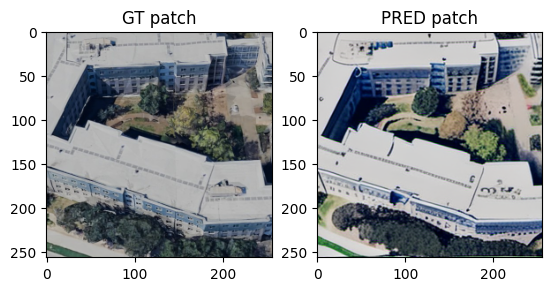

In [8]:
import matplotlib.pyplot as plt

# 取第一对整图
gt = cv2.imread(pairs[0][0])
pr = cv2.imread(pairs[0][1])
gt_rgb = cv2.cvtColor(gt, cv2.COLOR_BGR2RGB)
pr_rgb = cv2.cvtColor(pr, cv2.COLOR_BGR2RGB)

# 切分
gt_patches = split_2x2(gt_rgb)
pr_patches = split_2x2(pr_rgb)

# 并排显示第 i 个子图
i = 0  # 0=左上, 1=右上, 2=左下, 3=右下
fig, axes = plt.subplots(1, 2)
axes[0].imshow(gt_patches[i])
axes[0].set_title("GT patch")
axes[1].imshow(pr_patches[i])
axes[1].set_title("PRED patch")
plt.show()

In [9]:
gt = gt_patches_all[0]   # uint8, HWC
pr = pred_patches_all[0]
diff = np.abs(gt.astype(np.float32) - pr.astype(np.float32))
print("MAE (平均绝对误差):", diff.mean())
print("MSE:", np.mean((gt - pr)**2))

MAE (平均绝对误差): 36.716885
MSE: 106.70676167805989


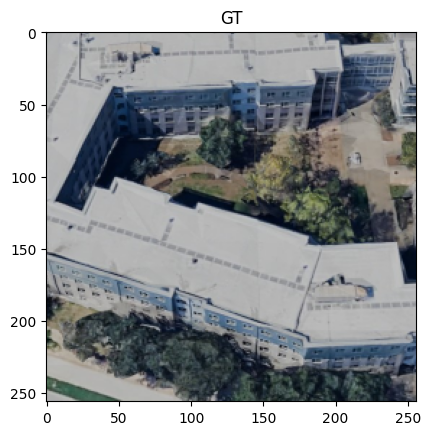

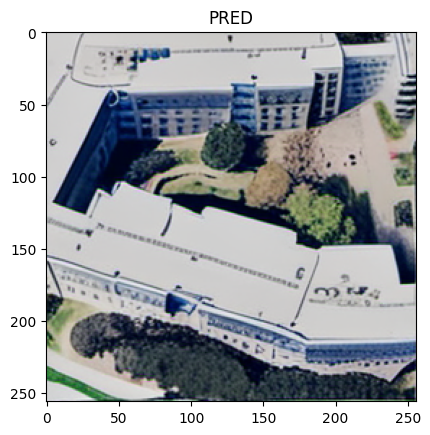

In [10]:
import matplotlib.pyplot as plt
plt.imshow(gt)        # 应该是正常彩色图
plt.title("GT")
plt.show()
plt.imshow(pr)
plt.title("PRED")
plt.show()

In [13]:
from skimage.metrics import peak_signal_noise_ratio as psnr
v = psnr(gt, pr, data_range=255)
print(v)

14.658040275016448


In [16]:
print(f"gt patch dtype={gt_patch.dtype}, min={gt_patch.min():.2f}, max={gt_patch.max():.2f}")
print(f"pred patch dtype={pred_patch.dtype}, min={pred_patch.min():.2f}, max={pred_patch.max():.2f}")

gt patch dtype=uint8, min=0.00, max=197.00
pred patch dtype=uint8, min=0.00, max=255.00
